# Atividade II
Julia Egute de Paula Machado



In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
SEED = 42
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

## Cenário anterior à ligação
Reutilizei a limpeza da Atividade I, preservando a ordem das linhas para reproduzir a divisão. Mês, dia e canal representam um contato já planejado.

In [5]:
try:
    dados = pd.read_csv("bank_marketing_completo-1.csv")
except FileNotFoundError:
    dados = pd.read_csv("bank_marketing_completo.csv")
dados = dados.drop_duplicates().copy()
alvo = dados.pop("aderiu").str.strip().str.lower().map({"sim":1, "não":0, "nao":0})
assert alvo.notna().all()
X = dados.drop(columns=["duracao_ligacao_seg","contatos_campanha_atual"])
col = "dias_desde_ultimo_contato"
X["nunca_contatado"] = X[col].eq(999).astype(int)
X[col] = X[col].replace(999, np.nan)
xt, xv, yt, yv = train_test_split(X, alvo.astype(int), test_size=.30, stratify=alvo, random_state=SEED)
print(pd.concat([yt.value_counts(), yv.value_counts()],axis=1,keys=["Treino","Teste"]))

        Treino  Teste
aderiu               
0        25576  10961
1         3247   1392


## Preparação e busca
Medianas e categorias são estimadas dentro de cada dobra. Padronizamos atributos numéricos para regressão e SVM. Árvores usam pontos de corte e dispensam padronização. Testei pesos originais e balanceados nos três métodos principais. F1 da adesão concilia perdas de clientes e desperdício de chamadas.

In [7]:
num = xt.select_dtypes("number").columns.tolist()
cat = xt.select_dtypes(exclude="number").columns.tolist()
def pipeline(modelo, escala):
    etapas = [("mediana", SimpleImputer(strategy="median"))]
    if escala:
        etapas.append(("escala", StandardScaler()))
    prep = ColumnTransformer([("num",Pipeline(etapas),num),("cat",OneHotEncoder(
        drop="first", handle_unknown="ignore", sparse_output=False),cat)])
    return Pipeline([("prep",prep),("modelo",modelo)])

pesos = [None,"balanced"]
opcoes = {
    "Logística": (LogisticRegression(max_iter=1000,random_state=SEED),True,{"C":[.1,1,10],"class_weight":pesos}),
    "SVM linear": (SVC(kernel="linear",random_state=SEED),True,{"C":[.1,1],"class_weight":pesos}),
    "SVM RBF": (SVC(kernel="rbf",random_state=SEED),True,{"C":[.1,1],"gamma":["scale",.1],"class_weight":pesos}),
    "Random Forest": (RandomForestClassifier(random_state=SEED,n_jobs=-1),False,
        {"n_estimators":[100,200],"max_depth":[8,None],"max_features":["sqrt",.5],"class_weight":pesos}),
    "Boosting": (GradientBoostingClassifier(random_state=SEED),False,{"n_estimators":[50,100]})}
if XGBClassifier is not None:
    opcoes["XGBoost"] = (XGBClassifier(random_state=SEED,n_jobs=2,eval_metric="logloss"),
                          False,{"n_estimators":[50,100],"max_depth":[3,5]})
else:
    print("Teste adicional de XGBoost pendente: o pacote externo não está instalado.")
xa, _, ya, _ = train_test_split(xt,yt,train_size=5000,stratify=yt,random_state=SEED)
buscas = {}
for nome,(modelo,escala,grade) in opcoes.items():
    x,y = (xa,ya) if nome.startswith("SVM") else (xt,yt)
    busca = GridSearchCV(pipeline(modelo,escala),{"modelo__"+k:v for k,v in grade.items()},
                         scoring="f1",cv=cv,refit=False,error_score="raise")
    busca.fit(x,y)
    buscas[nome] = busca
    print(nome, len(y), busca.best_params_, round(busca.best_score_,4))

Logística 28823 {'modelo__C': 10, 'modelo__class_weight': 'balanced'} 0.4458


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


SVM linear 5000 {'modelo__C': 0.1, 'modelo__class_weight': 'balanced'} 0.4511


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

SVM RBF 5000 {'modelo__C': 1, 'modelo__class_weight': 'balanced', 'modelo__gamma': 'scale'} 0.4533
Random Forest 28823 {'modelo__class_weight': 'balanced', 'modelo__max_depth': 8, 'modelo__max_features': 0.5, 'modelo__n_estimators': 100} 0.4806
Boosting 28823 {'modelo__n_estimators': 100} 0.3596
XGBoost 28823 {'modelo__max_depth': 5, 'modelo__n_estimators': 100} 0.3747


## Validação e ajuste final
Escolhi o kernel na amostra pelo F1 médio. Avaliei a configuração escolhida em cinco dobras do treino completo. O cronômetro mede somente o ajuste final do pipeline.

In [8]:
kernel = max(["SVM linear","SVM RBF"],key=lambda n:buscas[n].best_score_)
finais, validacao, tempos = {},{},{}
for nome,(modelo,escala,_) in opcoes.items():
    if nome.startswith("SVM") and nome != kernel:
        continue
    b = buscas[nome]
    p = pipeline(clone(modelo),escala).set_params(**b.best_params_)
    if nome == kernel:
        scores = cross_val_score(p,xt,yt,cv=cv,scoring="f1")
    else:
        scores = [b.cv_results_[f"split{i}_test_score"][b.best_index_] for i in range(5)]
    validacao[nome] = (np.mean(scores),np.std(scores))
    inicio = time.perf_counter()
    finais[nome] = p.fit(xt,yt)
    tempos[nome] = time.perf_counter()-inicio
principal = ["Logística",kernel,"Random Forest"]
sv = finais[kernel][-1].n_support_
print("Vetores de suporte por classe:",sv, "Fração do treino:", sv.sum()/len(yt))

Vetores de suporte por classe: [14192  2472] Fração do treino: 0.5781493945807168


## Teste reservado e capacidade
Cada modelo usa o limiar padrão para classificar e um escore contínuo para ordenar. Arredondei a capacidade para baixo para respeitar o limite. Empates preservam a ordem do teste.

In [9]:
linhas, matrizes, escores = {},{},{}
k = len(yv)//5
def capacidade(indices):
    acertos = int(yv.iloc[indices].sum())
    return [acertos,acertos/yv.sum(),acertos/len(indices)]
for nome,p in finais.items():
    pred = p.predict(xv)
    s = p.decision_function(xv) if hasattr(p,"decision_function") else p.predict_proba(xv)[:,1]
    escores[nome] = s
    r = classification_report(yv,pred,output_dict=True,zero_division=0)
    matrizes[nome] = confusion_matrix(yv,pred,labels=[0,1])
    linhas[nome] = [r["accuracy"]]+[r[c][m] for c in ["0","1"] for m in ["precision","recall","f1-score"]]+[
        roc_auc_score(yv,s),average_precision_score(yv,s),*validacao[nome],tempos[nome],
        *capacidade(np.argsort(-s,kind="stable")[:k])]
cols = ["Acur.","P não","R não","F1 não","P sim","R sim","F1 sim","AUC","AP","CV","DP","Seg.","Capt.","Cobert.","P@20%"]
tabela = pd.DataFrame.from_dict(linhas,orient="index",columns=cols)
aleatorio = capacidade(np.random.RandomState(SEED).choice(len(yv),k,replace=False))
print(tabela.round(4).to_string())
print("Aleatório:",aleatorio,"Esperado:",k*yv.mean())

                Acur.   P não   R não  F1 não   P sim   R sim  F1 sim     AUC      AP      CV      DP     Seg.  Capt.  Cobert.   P@20%
Logística      0.8332  0.9499  0.8573  0.9012  0.3642  0.6437  0.4652  0.8030  0.4464  0.4458  0.0135   0.8883    897   0.6444  0.3632
SVM RBF        0.8553  0.9499  0.8835  0.9155  0.4082  0.6329  0.4963  0.7825  0.3761  0.4708  0.0129  82.2505    910   0.6537  0.3684
Random Forest  0.8612  0.9487  0.8918  0.9194  0.4212  0.6200  0.5016  0.8116  0.4747  0.4806  0.0165   3.0165    910   0.6537  0.3684
Boosting       0.9008  0.9107  0.9849  0.9463  0.6673  0.2392  0.3522  0.8099  0.4744  0.3596  0.0143   6.1127    908   0.6523  0.3676
XGBoost        0.8974  0.9122  0.9786  0.9442  0.6050  0.2586  0.3624  0.8004  0.4515  0.3747  0.0165   0.5280    903   0.6487  0.3656
Aleatório: [282, np.float64(0.2025862068965517), 0.11417004048582996] Esperado: 278.3323888933862


## Figuras de avaliação

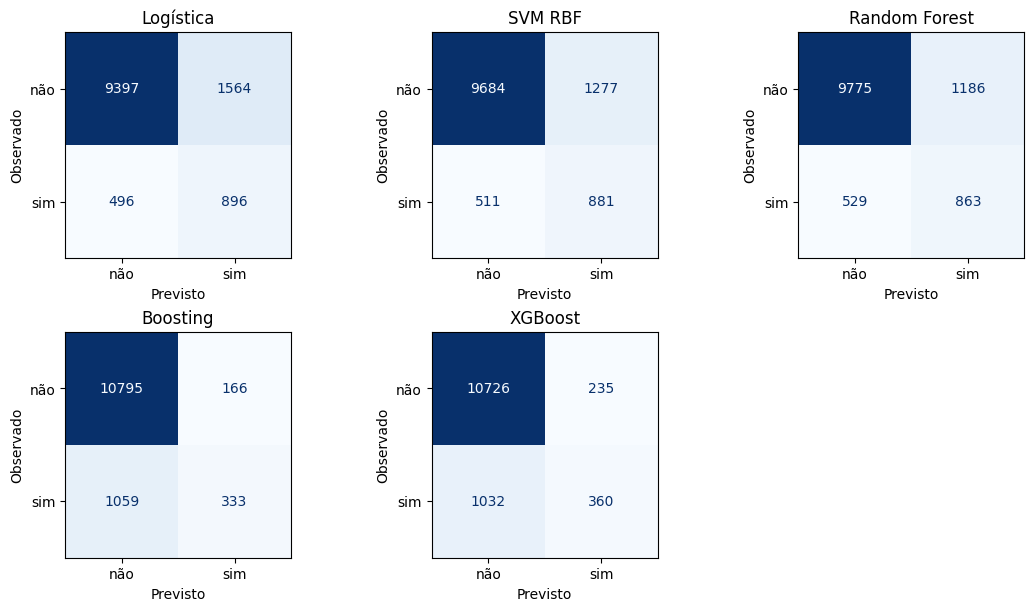

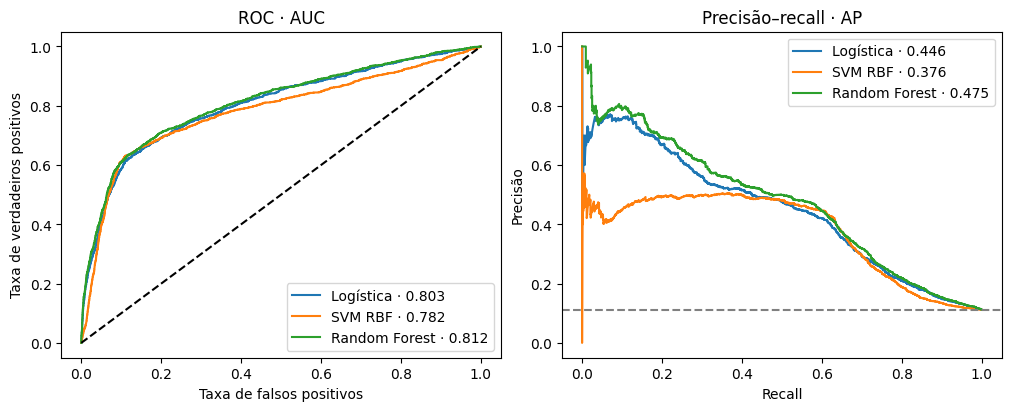

In [10]:
fig_cm,axes = plt.subplots(2,3,figsize=(11,6),layout="constrained")
for ax in axes.flat:
    ax.set_visible(False)
for ax,(nome,cm) in zip(axes.flat,matrizes.items()):
    ax.set_visible(True)
    ConfusionMatrixDisplay(cm,display_labels=["não","sim"]).plot(ax=ax,colorbar=False,cmap="Blues",values_format="d")
    ax.set(title=nome,xlabel="Previsto",ylabel="Observado")
fig_curvas,axes = plt.subplots(1,2,figsize=(10,4),layout="constrained")
for nome in principal:
    s = escores[nome]
    fpr,tpr,_ = roc_curve(yv,s)
    pr,rc,_ = precision_recall_curve(yv,s)
    axes[0].plot(fpr,tpr,label=f"{nome} · {tabela.loc[nome,'AUC']:.3f}")
    axes[1].plot(rc,pr,label=f"{nome} · {tabela.loc[nome,'AP']:.3f}")
axes[0].plot([0,1],[0,1],"k--")
axes[1].axhline(yv.mean(),ls="--",color="gray")
axes[0].set(title="ROC · AUC",xlabel="Taxa de falsos positivos",ylabel="Taxa de verdadeiros positivos")
axes[1].set(title="Precisão–recall · AP",xlabel="Recall",ylabel="Precisão")
for ax in axes: ax.legend()
plt.show()

## Interpretação
A importância por permutação mede a queda no F1 após embaralhar um atributo original no teste, com o modelo já fixado. Somei as importâncias por impureza dos indicadores de cada atributo para permitir a comparação.

In [11]:
lr = finais["Logística"]
enc = lr[0].named_transformers_["cat"]
nomes = list(num)
origem = list(num)
for c, categorias in zip(cat,enc.categories_):
    for nivel in categorias[1:]:
        nomes.append(f"{c}: {nivel} vs {categorias[0]}")
        origem.append(c)
coef = pd.Series(lr[-1].coef_[0],index=nomes)
top = coef.loc[coef.abs().nlargest(5).index]
rf = finais["Random Forest"]
mdi = pd.Series(rf[-1].feature_importances_,index=origem).groupby(level=0).sum()
imp = permutation_importance(rf,xv,yv,scoring="f1",n_repeats=5,random_state=SEED)
perm = pd.Series(imp.importances_mean,index=xv.columns)
print(top)
print(pd.concat([mdi,perm],axis=1,keys=["Impureza","Permutação"]).sort_values("Permutação",ascending=False))

taxa_variacao_emprego                    -2.329637
mes: mar vs abr                           1.471547
indice_precos_consumidor                  1.058093
euribor_3m                                0.761696
meio_contato: telefone_fixo vs celular   -0.691220
dtype: float64
                             Impureza  Permutação
numero_empregados            0.369145    0.126250
mes                          0.040448    0.025304
indice_confianca_consumidor  0.081754    0.016288
euribor_3m                   0.204800    0.016113
meio_contato                 0.014323    0.012722
dia_semana                   0.016841    0.011426
inadimplente                 0.008098    0.003738
idade                        0.040562    0.002840
resultado_campanha_anterior  0.012959    0.002759
nunca_contatado              0.024417    0.002474
indice_precos_consumidor     0.019836    0.002321
financiamento_imobiliario    0.005598    0.002063
contatos_anteriores          0.005214    0.001713
escolaridade                 0

## Relatório técnico
O PDF utiliza as tabelas, interpretações e figuras calculadas acima.

In [12]:
# Formatação dos números no padrão brasileiro.
def numero(valor, casas=0):
    texto = f"{valor:,.{casas}f}"
    return texto.translate(str.maketrans({",": ".", ".": ","}))


def porcentagem(valor, casas=2):
    return numero(100 * valor, casas) + "%"


def pagina(pdf, titulo, blocos):
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(
        .08, .94, titulo, fontsize=17, weight="bold",
        color="#174762", va="top"
    )

    # Organizo as linhas antes de desenhar para distribuir o texto na página.
    paragrafos = []
    for paragrafo in blocos:
        linhas = []
        linha = ""
        for palavra in paragrafo.split():
            candidata = (linha + " " + palavra).strip()
            if linha and len(candidata) > 83:
                linhas.append(linha)
                linha = palavra
            else:
                linha = candidata
        if linha:
            linhas.append(linha)
        paragrafos.append(linhas)

    total_linhas = sum(len(linhas) for linhas in paragrafos)
    intervalo = min(.024, .78 / max(1, total_linhas + len(paragrafos)))
    y = .87

    for linhas in paragrafos:
        for linha in linhas:
            fig.text(.08, y, linha, fontsize=10, va="top")
            y -= intervalo
        y -= intervalo * .7

    pdf.savefig(fig)
    plt.close(fig)


with PdfPages("Atividade_II_Relatorio.pdf") as pdf:

    # 1. Introdução e modelagem
    pagina(pdf, "1  Introdução e modelagem", [
        "Bank Marketing • Julia Egute de Paula Machado",

        "O banco precisa decidir para quais clientes ligar antes de saber quem vai "
        "aderir ao depósito a prazo. Comparei os classificadores para responder a "
        "duas perguntas: qual deles identifica melhor os clientes que aderem e "
        "qual permite encontrar mais adesões quando a central só pode ligar para "
        "20% da lista?",

        f"Retomei a base da Atividade I. Dos 41.188 registros originais, mantive "
        f"41.176 após excluir 12 duplicatas exatas. Como a base não identifica "
        f"cada contato, é possível que algumas linhas iguais correspondam a "
        f"ligações distintas. Reservei 30% da base para teste, com divisão "
        f"estratificada e semente 42. O treino ficou com {numero(len(yt))} "
        f"registros e o teste com {numero(len(yv))}, dos quais "
        f"{numero(yv.sum())} correspondem a adesões.",

        "Excluí a duração da ligação porque ela só é conhecida depois do contato. "
        "Também retirei a contagem da campanha atual, pois ela inclui a própria "
        "ligação registrada. Mantive mês, dia da semana e canal sob a hipótese de "
        "que o banco já definiu essas informações ao organizar a lista. Na coluna "
        "de dias desde o último contato, substituí o código 999 por um valor "
        "ausente e criei o indicador nunca_contatado. Mantive a categoria "
        "“desconhecido” nos atributos categóricos.",

        "Escolhi o F1 da classe “sim” como métrica principal. Na Atividade I, "
        "usei o F1 macro, que dá o mesmo peso às duas classes. Para esta campanha, "
        "interessa saber quantos clientes que aderem o modelo consegue encontrar "
        "(recall) e quantas das indicações de adesão estão corretas (precisão). "
        "O F1 da classe “sim” reúne essas duas medidas.",

        "Em cada dobra, ajustei a mediana dos atributos numéricos e a codificação "
        "one-hot das categorias dentro do pipeline. Usei a primeira categoria de "
        "cada atributo como referência. Padronizei os atributos numéricos na "
        "regressão logística e no SVM, pois a escala influencia a regularização "
        "e o cálculo das distâncias. Nas árvores, mantive a escala original, já "
        "que as divisões dependem da ordem dos valores.",

        "Comparei pesos uniformes e balanceados nos três classificadores "
        "principais. Com pesos balanceados, um erro na classe minoritária recebe "
        "maior peso no ajuste. Mantive os limiares de classificação padrão. Nos "
        "testes complementares de Boosting e XGBoost, usei pesos uniformes.",

        "Escolhi os hiperparâmetros pelo maior F1 médio em cinco dobras "
        "estratificadas do treino, com embaralhamento e semente 42. Para reduzir "
        "o tempo de busca do SVM, comparei os kernels em uma amostra estratificada "
        "de 5.000 registros. Depois, avaliei o kernel escolhido em cinco dobras "
        "do treino completo. Ajustei cada modelo final com todos os dados de treino "
        "antes de avaliar o desempenho no teste."
    ])

    # 2. Configurações avaliadas
    detalhes = []

    for nome, (_, _, grade) in opcoes.items():
        busca = buscas[nome]
        config = {
            chave.replace("modelo__", ""): valor
            for chave, valor in busca.best_params_.items()
        }

        valores_testados = []
        for parametro, valores in grade.items():
            opcoes_texto = ", ".join(str(valor) for valor in valores)
            valores_testados.append(f"{parametro} ({opcoes_texto})")

        config_texto = ", ".join(
            f"{parametro} = {valor}" for parametro, valor in config.items()
        )

        detalhes.append(
            f"{nome}. Testei {' e '.join(valores_testados)}. "
            f"A configuração com maior F1 médio foi {config_texto}, "
            f"com F1 de {numero(busca.best_score_, 4)} na busca."
        )

    detalhes.append(
        f"Escolhi o {kernel} pelo F1 médio na comparação entre os dois kernels. "
        f"No ajuste final, {numero(sv.sum())} registros se tornaram vetores de "
        f"suporte: {numero(sv[0])} da classe “não” e {numero(sv[1])} da classe "
        f"“sim”. Isso corresponde a {porcentagem(sv.sum() / len(yt), 1)} do treino. "
        f"O modelo usa esses exemplos para calcular a pontuação de novos clientes. "
        f"Portanto, mais da metade dos registros de treino participa desse cálculo."
    )

    if XGBClassifier is None:
        detalhes.append(
            "O pacote xgboost estava indisponível nesta execução. Por esse motivo, "
            "não obtive resultados para o teste complementar de XGBoost."
        )

    pagina(pdf, "2  Configurações avaliadas", detalhes)

    # 3. Resultados comparativos
    fig, ax = plt.subplots(figsize=(11.69, 8.27))
    ax.axis("off")
    ax.set_title(
        "3  Resultados comparativos", loc="left",
        fontsize=18, weight="bold"
    )

    quadro = tabela.T.copy()
    quadro["Aleatório"] = np.nan
    quadro.loc[["Capt.", "Cobert.", "P@20%"], "Aleatório"] = aleatorio

    textos = []
    for indicador, linha in quadro.iterrows():
        valores = []
        for valor in linha:
            if pd.isna(valor):
                valores.append("—")
            elif indicador == "Capt.":
                valores.append(numero(valor))
            else:
                valores.append(numero(valor, 3))
        textos.append(valores)

    tab = ax.table(
        cellText=textos,
        rowLabels=quadro.index,
        colLabels=quadro.columns,
        loc="center",
        cellLoc="center"
    )
    tab.auto_set_font_size(False)
    tab.set_fontsize(9)
    tab.scale(.95, 1.6)

    ax.text(
        0, .055,
        "P = precisão · R = recall · CV e DP = média e desvio-padrão do F1 da "
        "classe “sim” no treino · Seg. = tempo do ajuste final",
        fontsize=9
    )
    ax.text(
        0, .025,
        f"Capt. = adesões entre os {numero(k)} selecionados · Cobert. = parcela "
        "das adesões encontradas · P@20% = precisão entre os selecionados",
        fontsize=9
    )
    ax.text(
        0, -.005,
        "AUC = área sob a curva ROC · AP = precisão média · "
        "O sorteio serve de referência para o cenário de 20% das chamadas.",
        fontsize=9
    )

    pdf.savefig(fig)
    plt.close(fig)

    pdf.savefig(fig_cm)
    pdf.savefig(fig_curvas)

    # Interpretação dos cinco coeficientes e das importâncias da floresta.
    interpretacoes = [
        "Para interpretar a regressão logística, selecionei os cinco coeficientes "
        "de maior valor absoluto e preservei seus sinais. As comparações abaixo "
        "mantêm os demais atributos fixos. A chance de adesão corresponde à "
        "probabilidade de aderir dividida pela probabilidade de não aderir."
    ]

    for atributo, beta in top.items():
        fator = np.exp(beta)
        variacao = porcentagem(abs(fator - 1), 1)
        direcao = "maior" if beta > 0 else "menor"
        coeficiente = numero(beta, 3)

        if atributo in num:
            descricao = atributo.replace("_", " ")
            frase = (
                f"Para {descricao}, um aumento de um desvio-padrão está associado "
                f"a uma chance de adesão {variacao} {direcao} "
                f"(coeficiente {coeficiente})."
            )
        else:
            campo, categorias = atributo.split(": ", 1)
            nivel, referencia = categorias.split(" vs ", 1)
            frase = (
                f"No atributo {campo.replace('_', ' ')}, a chance estimada de "
                f"adesão para a categoria “{nivel.replace('_', ' ')}” é "
                f"{variacao} {direcao} que para a categoria "
                f"“{referencia.replace('_', ' ')}” (coeficiente {coeficiente})."
            )
        interpretacoes.append(frase)

    maiores_mdi = mdi.nlargest(5)
    maiores_perm = perm.nlargest(5)

    lista_mdi = ", ".join(
        f"{nome.replace('_', ' ')} ({numero(valor, 3)})"
        for nome, valor in maiores_mdi.items()
    )
    lista_perm = ", ".join(
        f"{nome.replace('_', ' ')} ({numero(valor, 3)})"
        for nome, valor in maiores_perm.items()
    )

    atributos_logistica = {origem[nomes.index(atributo)] for atributo in top.index}
    comuns = [
        nome.replace("_", " ")
        for nome in maiores_perm.index
        if nome in atributos_logistica
    ]

    interpretacoes.extend([
        "Na Random Forest, somei as reduções de impureza dos indicadores de cada "
        f"atributo original. Os cinco maiores valores foram {lista_mdi}.",

        "Também embaralhei cada atributo cinco vezes no teste e medi a queda média "
        f"no F1 da classe “sim”. As maiores quedas ocorreram em {lista_perm}.",

        f"Entre os destaques da regressão logística e da importância por permutação, "
        f"os atributos em comum foram {', '.join(comuns) if comuns else 'nenhum'}. "
        "Na logística, o sinal do coeficiente indica a direção da associação. "
        "Na floresta, a queda de F1 mostra quanto o modelo dependeu daquele atributo "
        "para classificar os clientes. Quando dois atributos são correlacionados, "
        "um pode compensar parte da informação perdida ao embaralhar o outro."
    ])

    pagina(pdf, "3  Interpretação dos atributos", interpretacoes)

    # 4. Indicação do classificador
    principais = tabela.loc[principal]
    lider_f1 = principais["CV"].idxmax()

    maior_captura = principais["Capt."].max()
    lideres_captura = principais[principais["Capt."] == maior_captura]
    recomendado = lideres_captura["Seg."].idxmin()

    analise = [
        f"Na validação cruzada, o maior F1 médio da classe “sim” foi o de "
        f"{lider_f1}: {numero(principais.loc[lider_f1, 'CV'], 4)}, com "
        f"desvio-padrão de {numero(principais.loc[lider_f1, 'DP'], 4)}."
    ]

    for nome in principal:
        if nome == lider_f1:
            continue

        diferenca = principais.loc[lider_f1, "CV"] - principais.loc[nome, "CV"]
        desvios = [
            principais.loc[lider_f1, "DP"],
            principais.loc[nome, "DP"]
        ]

        if diferenca <= min(desvios):
            leitura = (
                "A diferença é menor ou igual aos dois desvios-padrão. Por esse "
                "critério, não identifico uma vantagem clara em F1."
            )
        elif diferenca <= max(desvios):
            leitura = (
                "A diferença fica dentro do desvio-padrão de um dos modelos. "
                "Por isso, interpreto essa vantagem com cautela."
            )
        else:
            leitura = (
                "A diferença supera os dois desvios-padrão observados nas dobras."
            )

        analise.append(
            f"Na comparação entre {lider_f1} e {nome}, a diferença de F1 médio "
            f"foi de {numero(diferenca, 4)}. {leitura}"
        )

    if len(lideres_captura) > 1:
        nomes_empatados = " e ".join(lideres_captura.index)
        analise.append(
            f"Com o limite de {numero(k)} chamadas, {nomes_empatados} empataram. "
            f"Cada um encontrou {numero(maior_captura)} dos {numero(yv.sum())} "
            f"clientes que aderiram. Isso representa "
            f"{porcentagem(principais.loc[recomendado, 'Cobert.'])} de todas as "
            f"adesões do teste. Entre os clientes selecionados, "
            f"{porcentagem(principais.loc[recomendado, 'P@20%'])} aderiram. "
            f"Como os dois atenderam igualmente bem à capacidade da central, "
            f"recomendo {recomendado} pelo menor tempo de ajuste."
        )
    else:
        analise.append(
            f"Com o limite de {numero(k)} chamadas, recomendo {recomendado}. "
            f"O modelo encontrou {numero(maior_captura)} dos {numero(yv.sum())} "
            f"clientes que aderiram, o maior total entre os três classificadores."
        )

    capturas = ", ".join(
        f"{nome} ({numero(principais.loc[nome, 'Capt.'])})" for nome in principal
    )
    tempos_texto = ", ".join(
        f"{nome} ({numero(principais.loc[nome, 'Seg.'], 2)} s)" for nome in principal
    )

    analise.extend([
        f"Para o mesmo número de chamadas, a seleção aleatória encontrou "
        f"{numero(aleatorio[0])} adesões. Entre os três classificadores, os "
        f"totais foram {capturas}. Em relação ao sorteio, o modelo recomendado "
        f"encontrou {numero(maior_captura - aleatorio[0])} adesões a mais.",

        f"Os tempos de treinamento final foram {tempos_texto}. Para os gestores, "
        "a floresta permite mostrar quais informações tiveram maior importância "
        "na priorização. No SVM com kernel RBF, é mais difícil explicar por que "
        "um cliente específico recebeu uma pontuação alta.",

        "Se o banco precisar justificar a direção de cada associação, eu daria "
        "preferência à regressão logística. Seus coeficientes permitem explicar, "
        "por exemplo, como muda a chance estimada de adesão ao comparar dois "
        "canais de contato, mantendo os demais atributos fixos."
    ])

    pagina(pdf, "4  Indicação do classificador", analise)

    discussao = [
        f"Apenas {porcentagem(yv.mean())} dos clientes do teste aderiram. Na "
        "curva ROC, a taxa de falsos positivos é calculada sobre todos os clientes "
        "que não aderiram. Como esse grupo é grande, mesmo uma taxa baixa pode "
        "representar muitas ligações improdutivas. Para a central, a curva "
        "precisão–recall é mais informativa porque mostra qual parcela da lista "
        "selecionada realmente aderiu à medida que o modelo passa a encontrar "
        "mais clientes da classe “sim”.",

        f"A Random Forest teve precisão média (AP) de "
        f"{numero(tabela.loc['Random Forest', 'AP'], 4)}, e o {kernel}, de "
        f"{numero(tabela.loc[kernel, 'AP'], 4)}. A AP resume o desempenho ao "
        "longo de vários pontos de corte. Já a central trabalha com um corte "
        "específico: os primeiros 20% da lista. Isso explica por que dois modelos "
        "com APs diferentes podem encontrar a mesma quantidade de adesões dentro "
        "da capacidade disponível.",

        "Ao comparar modelos de complexidades diferentes, percebi que a escolha "
        "depende de como o banco vai usar a previsão. O F1 avalia as decisões de "
        "classe no limiar adotado. Na campanha, também importa a ordem da lista, "
        "porque um cliente pode receber uma das maiores pontuações e entrar nas "
        "primeiras ligações mesmo sem ultrapassar o limiar de classificação."
    ]

    if "Boosting" in tabela.index and "XGBoost" in tabela.index:
        discussao.append(
            f"Essa diferença apareceu nos testes complementares. No limiar padrão, "
            f"o recall da classe “sim” foi de "
            f"{porcentagem(tabela.loc['Boosting', 'R sim'])} para o Boosting e "
            f"{porcentagem(tabela.loc['XGBoost', 'R sim'])} para o XGBoost. "
            f"Ainda assim, nas primeiras {numero(k)} posições, esses modelos "
            f"encontraram {numero(tabela.loc['Boosting', 'Capt.'])} e "
            f"{numero(tabela.loc['XGBoost', 'Capt.'])} adesões, respectivamente."
        )

    discussao.extend([
        "A divisão aleatória permitiu comparar os modelos nas mesmas condições, "
        "mas não mostra se o desempenho se mantém em uma campanha posterior. "
        "Além disso, usar as mesmas dobras para escolher e resumir a melhor "
        "configuração pode favorecer o resultado da validação. Como próximo passo, "
        "eu avaliaria a lista em outra campanha e verificaria se o banco realmente "
        "conhece o dia e o canal ao decidir para quem ligar.",

        "6  Declaração de uso de IA generativa",

        "Usei o ChatGPT como apoio na elaboração do código e revisão do relatório. Executei o notebook no Google Colab. As tabelas, os gráficos e os valores apresentados vieram das saídas dessa execução."
    ])

    pagina(pdf, "5  Discussão e conclusão", discussao)

print("Relatório gerado: Atividade_II_Relatorio.pdf")

Relatório gerado: Atividade_II_Relatorio.pdf
